# Cleaning MBTA Subway Data

I downloaded CSV files for the 2024 headway files from the MBTA open data site. For now, I'm just going to consider the Green Line before trying to analyze additional transit lines.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import glob

## Load the data
The files are big so we only load the columns we need and filter to the Green Line one month at a time.

In [2]:
cols = ['service_date', 'route_id', 'trip_id', 'direction_id', 'direction', 'parent_station',
        'stop_name', 'stop_departure_sec', 'headway_trunk_seconds', 'headway_branch_seconds']

files = sorted(glob.glob('data/Headways_2024/*.csv'))
months = []
for f in files:
    month = pd.read_csv(f, usecols=cols)
    month = month[month['route_id'].str.startswith('Green')]
    months.append(month)
    print(f, len(month))

df = pd.concat(months, ignore_index=True)
print('total green line rows:', len(df))

data/Headways_2024/2024-01_Headway.csv 382456
data/Headways_2024/2024-02_Headway.csv 510450
data/Headways_2024/2024-03_Headway.csv 560142
data/Headways_2024/2024-04_Headway.csv 641050
data/Headways_2024/2024-05_Headway.csv 669976
data/Headways_2024/2024-06_Headway.csv 625055
data/Headways_2024/2024-07_Headway.csv 649258
data/Headways_2024/2024-08_Headway.csv 635897
data/Headways_2024/2024-09_Headway.csv 652600
data/Headways_2024/2024-10_Headway.csv 665129
data/Headways_2024/2024-11_Headway.csv 629728
data/Headways_2024/2024-12_Headway.csv 563148
total green line rows: 7184889


## Check how much each cleaning step removes

In [3]:
print('NONREV trips:', df['trip_id'].str.startswith('NONREV').sum())
print('ADDED trips:', df['trip_id'].str.startswith('ADDED').sum())
print('blank headways:', df['headway_trunk_seconds'].isna().sum())
print('headways under 30 sec:', (df['headway_trunk_seconds'] < 30).sum())
print('headways over 1 hour:', (df['headway_trunk_seconds'] > 3600).sum())
print('after midnight:', (df['stop_departure_sec'] >= 86400).sum())

NONREV trips: 26226
ADDED trips: 2656681
blank headways: 48880
headways under 30 sec: 110326
headways over 1 hour: 1456
after midnight: 313608


## Clean it

In [4]:
clean = df[~df['trip_id'].str.startswith('NONREV')]
clean = clean.dropna(subset=['headway_trunk_seconds'])
clean = clean[(clean['headway_trunk_seconds'] >= 30) & (clean['headway_trunk_seconds'] <= 3600)].copy()

# add some columns we'll want later
clean['service_date'] = pd.to_datetime(clean['service_date'])
clean['hour'] = clean['stop_departure_sec'] // 3600   # 24 and 25 = 12am and 1am
clean['day_of_week'] = clean['service_date'].dt.day_name()
clean['weekend'] = clean['service_date'].dt.dayofweek >= 5
clean['added_trip'] = clean['trip_id'].str.startswith('ADDED')
clean['headway_min'] = clean['headway_trunk_seconds'] / 60

print('rows before:', len(df))
print('rows after:', len(clean))
print('days:', clean['service_date'].nunique())
print('stations:', clean['parent_station'].nunique())

clean.to_csv('data/green_headways_clean.csv', index=False)
clean.head()

rows before: 7184889
rows after: 6998376
days: 366
stations: 68


,service_date,route_id,trip_id,direction_id,direction,parent_station,stop_name,stop_departure_sec,headway_trunk_seconds,headway_branch_seconds,hour,day_of_week,weekend,added_trip,headway_min
1,2024-01-01,Green-B,ADDED-1581739663,1,East,place-babck,Babcock Street,21207,690.0,690.0,5,Monday,False,True,11.500000
2,2024-01-01,Green-B,ADDED-1581739665,1,East,place-babck,Babcock Street,21801,594.0,594.0,6,Monday,False,True,9.900000
3,2024-01-01,Green-B,ADDED-1581739671,1,East,place-babck,Babcock Street,22112,311.0,311.0,6,Monday,False,True,5.183333
4,2024-01-01,Green-B,60564070,1,East,place-babck,Babcock Street,23046,934.0,934.0,6,Monday,False,False,15.566667
5,2024-01-01,Green-B,ADDED-1581739682,1,East,place-babck,Babcock Street,24433,1387.0,1387.0,6,Monday,False,True,23.116667


## Basic Checks

In [ ]:
# median wait (in minutes) and % of added trips for each branch
clean['branch_headway_min'] = clean['headway_branch_seconds'] / 60
clean.groupby('route_id').agg(
    rows=('trip_id', 'count'),
    median_wait=('branch_headway_min', 'median'),
    pct_added=('added_trip', 'mean')
)

,rows,median_wait,pct_added
route_id,,,
Green-B,1690671,9.150000,0.389542
Green-C,1471711,9.066667,0.325220
Green-D,1772724,9.566667,0.425382
Green-E,2063270,8.133333,0.321643


## Plot: wait between trains at Kenmore by hour

Kenmore is the stop for Fenway Park. We don't have the game schedule yet so for now this compares weekdays and weekends. Once we have the game dates we can swap it to game days vs non game days.

We use the median since a few really long gaps would throw off the mean.

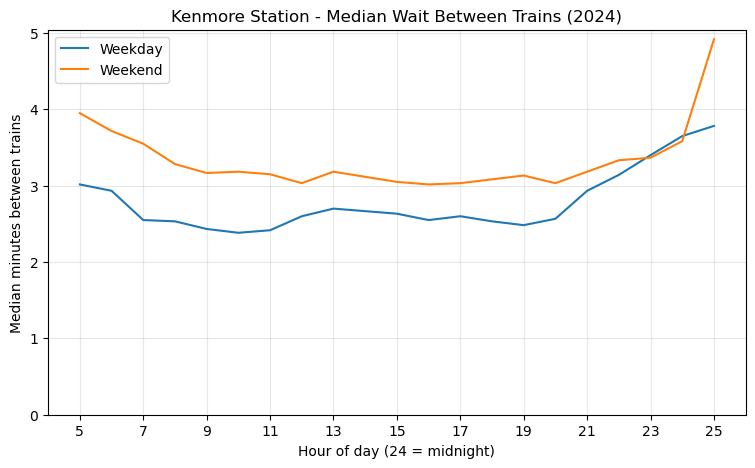

In [7]:
kenmore = clean[(clean['parent_station'] == 'place-kencl') & (clean['hour'] >= 5) & (clean['hour'] <= 25)]

weekday = kenmore[kenmore['weekend'] == False].groupby('hour')['headway_min'].median()
weekend = kenmore[kenmore['weekend'] == True].groupby('hour')['headway_min'].median()

plt.figure(figsize=(9, 5))
plt.plot(weekday.index, weekday.values, label='Weekday')
plt.plot(weekend.index, weekend.values, label='Weekend')
plt.xlabel('Hour of day (24 = midnight)')
plt.ylabel('Median minutes between trains')
plt.title('Kenmore Station - Median Wait Between Trains (2024)')
plt.xticks(range(5, 26, 2))
plt.ylim(bottom=0)
plt.legend()
plt.grid(alpha=0.3)
plt.savefig('figures/kenmore_headway_by_hour.png')
plt.show()

## Next steps
- Get the 2024 home game schedules for the Red Sox, Bruins and Celtics
- Remove shutdown days (the low row count days above, mostly January)
- Clean the travel times data the same way